# Example: RMDC26_001576 — a blind Roman event with a resonant caustic

The third blind example on simulated Roman data, after `example_rmdc26_000026` (a planetary caustic, one sharp
solution) and `example_rmdc26_001422` (a central caustic, a close/wide degeneracy). Here the source passes close to a
*resonant* caustic, the single large caustic that forms when a planet sits near the Einstein ring, and the anomaly
has a rich shape: a bump, a sharp drop, a trough and a second bump within a day.

**The data.** RMDC26_001576 is an event of the *Experienced tier* of the Roman Microlensing Data Challenge 2026
(RGES-PIT; public domain, CC0, [huggingface.co/datasets/RGES-PIT/Experienced](https://huggingface.co/datasets/RGES-PIT/Experienced)),
simulated with GULLS (Penny et al. 2019). The true parameters are not published, so this is a **blind** analysis.
The line of sight is heavily reddened: the challenge lists an extinction of 12.3 mag in F087, so the F087 points are
pure noise around zero flux. They stay in the fit with their own source and blend flux, where they do no harm.

**What this notebook does.** The same steps as `example_rmdc26_001422`, whose notebook explains them in more detail:
data reduction (49 488 → 1547 points), a single-lens fit, guided binary fits, a coarse map over 0.1 < *s* < 10 and
10⁻⁵ < *q* < 1, zooms at 4× and 64× into the valley, the polished best fit, light curve, caustics and a rough physical
scale.

**Runtime.** The coarse map took 22 minutes on a 14-core Intel Core i5-13500 (20 threads), the zooms 7.4 and 3.6
minutes, the guided fits 2 and the polish a few minutes. Everything is stored in `data/`, so the notebook runs in a
few seconds by default; `RECOMPUTE = True` computes it all again (about 45 minutes on a 20-thread desktop).

## 0. Setup

In [1]:
import os, time, json
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import figures, caustics, model

RECOMPUTE = False              # True: compute all maps and fits again (about an hour on a 20-thread desktop)
LOGFILE = os.environ.get("LENSCAPE_LOG")          # progress of long runs is also appended here if set


def log(msg):
    print(msg, flush=True)
    if LOGFILE:
        with open(LOGFILE, "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")

print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/rmdc1576_photometry.csv`: all points (none saturated), with `set` (filter), `t` (BJD − 2460000) and `flux`,
`flux_err` in micro-Jansky as provided. Magnitudes below are AB, 23.9 − 2.5 log₁₀(flux / µJy).

In [2]:
SETS = ["F087", "F146", "F213"]
rows = np.genfromtxt("data/rmdc1576_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
sel = lambda r, n: (r["t"][r["set"] == n], r["flux"][r["set"] == n], r["flux_err"][r["set"] == n])
data_all = lenscape.Data.from_sets({n: sel(rows, n) for n in SETS})
mag = lambda f: 23.9 - 2.5 * np.log10(f)                # AB magnitude of a flux in micro-Jansky
for n in SETS:
    t, f, e = sel(rows, n)
    print(f"{n}: {len(t)} points, median flux {np.median(f):9.4f} uJy, median error {np.median(e):.4f} uJy")

F087: 1501 points, median flux    0.0023 uJy, median error 0.2990 uJy
F146: 46488 points, median flux    4.8228 uJy, median error 0.1946 uJy
F213: 1499 points, median flux  106.8445 uJy, median error 0.9620 uJy


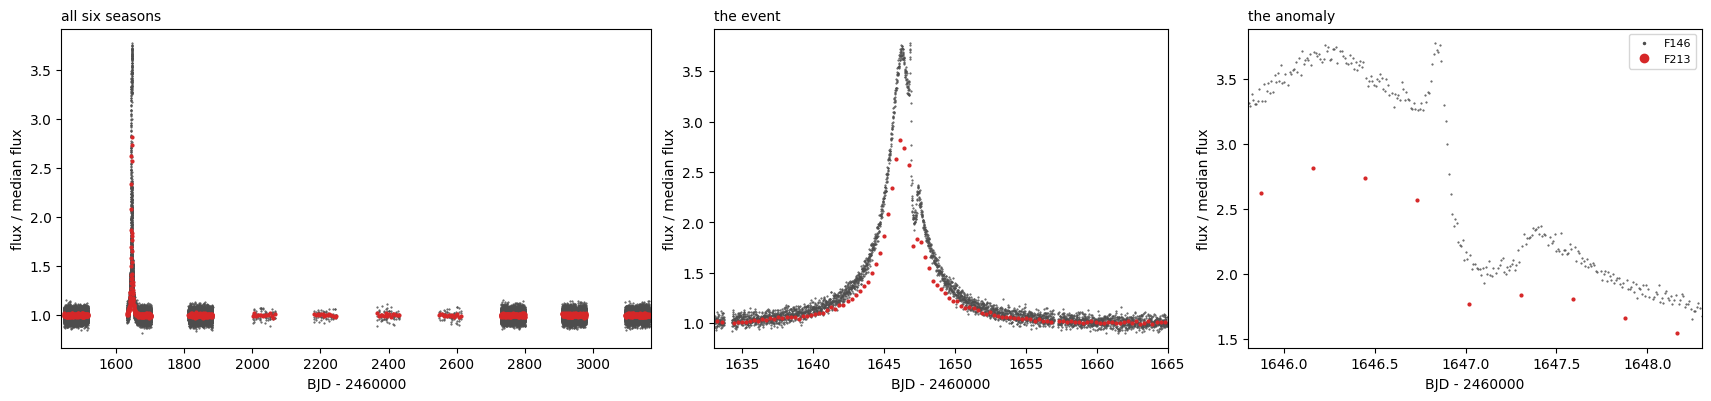

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(17, 3.9), gridspec_kw=dict(width_ratios=[1.3, 1, 1]), constrained_layout=True)
for ax, (a, b) in zip(axs, ((1440, 3170), (1633, 1665), (1645.8, 1648.3))):
    for n, c in (("F146", "0.3"), ("F213", "C3")):
        k = data_all.names.index(n)
        m = (data_all.idx == k) & (data_all.t > a) & (data_all.t < b)
        ax.plot(data_all.t[m], data_all.f[m] / np.median(data_all.f[data_all.idx == k]), ".", ms=1 if n == "F146" else 4,
                color=c, label=n, rasterized=True)
    ax.set_xlim(a, b); ax.set_xlabel("BJD - 2460000"); ax.set_ylabel("flux / median flux")
axs[0].set_title("all six seasons", loc="left", fontsize=10)
axs[1].set_title("the event", loc="left", fontsize=10)
axs[2].set_title("the anomaly", loc="left", fontsize=10); axs[2].legend(fontsize=8, markerscale=3)

The event peaks at BJD′ = 1646.2 (BJD′ = BJD − 2460000), at the start of the second season (the season begins
1.6 Einstein timescales before the peak). F146 brightens by a factor of 3.8, F213 by 2.9 (other stars contribute more of its baseline). Two-thirds of a day
after the peak the anomaly starts: a sharp spike, a sudden drop to less than half the brightness within a few hours,
a trough, and a second bump.

## 2. Reducing the data for the maps

The same reduction as in the other two examples: the second season only (BJD′ 1633–1704), F146 at full cadence over
the peak and the anomaly (BJD′ 1645.5–1648.5), in 1-hour bins within one Einstein timescale (*t*₀ = 1646.19,
*t*ₑ = 7.96 d) and 3-hour bins elsewhere; F087 and F213 unbinned.

In [4]:
SEASON = (1633.0, 1704.0)
ANOM = (1645.5, 1648.5)
T0_BIN, TE_BIN = 1646.19, 7.96
def reduce(rows):
    # season only; F146: full cadence in ANOM, 1-h bins within TE_BIN of T0_BIN, 3-h bins elsewhere
    out = {}
    for n in SETS:
        t, f, e = sel(rows, n)
        m = (t >= SEASON[0]) & (t <= SEASON[1])
        t, f, e = t[m], f[m], e[m]
        if n != "F146":
            out[n] = (t, f, e); continue
        full = (t >= ANOM[0]) & (t <= ANOM[1])
        inner = np.abs(t - T0_BIN) < TE_BIN
        key = np.floor((t - SEASON[0]) / np.where(inner, 1 / 24, 3 / 24)).astype(int) * 2 + inner
        b = ~full
        u, inv = np.unique(key[b], return_inverse=True)
        w = 1 / e[b] ** 2
        W = np.bincount(inv, w)
        T, F, E = (np.r_[t[full], np.bincount(inv, w * t[b]) / W], np.r_[f[full], np.bincount(inv, w * f[b]) / W],
                   np.r_[e[full], W ** -0.5])
        o = np.argsort(T)
        out[n] = (T[o], F[o], E[o])
    return lenscape.Data.from_sets(out)

data = reduce(rows)
season = data_all.window(*SEASON)
be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
print(f"all {len(data_all)} points, season {len(season)}, binned {len(data)}:",
      {n: len(s) for n, s in zip(data.names, data.slices)})

all 49488 points, season 8152, binned 1547: {'F087': 240, 'F146': 1068, 'F213': 239}


## 3. Single lens and guided fits

The anomaly starts about 0.1 Einstein timescales after the peak, when the source is still within ≈ 0.15 Einstein
radii of the host. A planet whose caustic reaches that far from the host must lie near the Einstein ring, where the
central and planetary caustics merge into one *resonant* caustic. The guided starts are the same broad set as for
RMDC26_001422 (log *s* = ±0.05 … ±0.8, log *q* = −5 … 0, three source sizes, 360 angles; the 24 best distinct starts
fitted, then the offset partners of the 8 best).

In [5]:
first_file = "data/rmdc1576_first_fits.json"
if RECOMPUTE or not os.path.exists(first_file):
    log("computing the guided fits")
    from scipy.optimize import minimize
    m = data.select(~((data.t >= ANOM[0]) & (data.t <= ANOM[1])))
    def c2_single(x):
        A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]) + 1e-3, 10 ** min(x[3], -0.5), m.t, 0.0)
        return model.chi2_profiled(A, m.f, m.w, m.idx, m.nsets)
    r = min((minimize(c2_single, [1646.19, u0, tE, -2.5], method="Nelder-Mead", options=dict(maxfev=4000, adaptive=True))
             for u0 in (0.02, 0.05, 0.1) for tE in (5.0, 10.0, 20.0)), key=lambda r: r.fun)
    sl = dict(t0=float(r.x[0]), u0=abs(float(r.x[1])), tE=abs(float(r.x[2])) + 1e-3)
    grid = lenscape.make_backend(lenscape.config.GRID_BACKEND)
    trials = []
    for ls in [v * sg for v in (0.05, 0.1, 0.2, 0.3, 0.5, 0.8) for sg in (1, -1)]:
        for lq in np.arange(-5.0, 0.01, 0.5):
            for lr in (-3.0, -2.5, -2.0):
                for a in np.arange(360) * 2 * np.pi / 360:
                    p = [sl["t0"], sl["u0"], sl["tE"], ls, float(lq), float(a), lr]
                    trials.append((model.chi2(grid, p, data), p))
    trials.sort(key=lambda r: r[0])
    def distinct(rows, n, ds, dq, da):
        out = []
        for c, p in rows:
            if all(abs(p[3] - q[3]) > ds or abs(p[4] - q[4]) > dq or abs(np.angle(np.exp(1j * (p[5] - q[5])))) > da
                   for _, q in out):
                out.append((c, p))
            if len(out) == n:
                break
        return out
    def full_fit(p):
        c, p = lenscape.fit_full(data, p, grid, rounds=2, maxfev=3000)
        c, p = lenscape.fit_full(data, p, be, rounds=2, maxfev=3000)
        return float(c), [float(v) for v in p]
    res = sorted((full_fit(p) for _, p in distinct(trials, 24, 0.01, 0.1, 0.15)), key=lambda r: r[0])
    res += [full_fit(lenscape.fit.offset_partner(np.array(p)).tolist()) for _, p in distinct(res, 8, 0.005, 0.05, 0.1)]
    json.dump(dict(single_lens=sl, fits=sorted(res, key=lambda r: r[0])), open(first_file, "w"), indent=1)
first = json.load(open(first_file))
sl = first["single_lens"]
print(f"single lens (anomaly masked): t0 = {sl['t0']:.3f}, u0 = {sl['u0']:.4f}, tE = {sl['tE']:.2f} d, "
      f"chi2 = {sl['chi2_all']:.0f} with the anomaly")
print(f"{'chi2':>9s} {'log s':>8s} {'log q':>7s} {'alpha':>6s} {'u0':>8s} {'tE':>7s} {'log rho':>7s}")
shown = []
for c, p in first["fits"]:
    if all(abs(p[3] - q[3]) > 0.003 or abs(p[4] - q[4]) > 0.03 for _, q in shown):
        shown.append((c, p))
        print(f"{c:9.2f} {p[3]:+8.4f} {p[4]:+7.3f} {p[5] % (2 * np.pi):6.3f} {p[1]:+8.5f} {p[2]:7.3f} {p[6]:+7.3f}")
best_first = np.array(first["fits"][0][1])

single lens (anomaly masked): t0 = 1646.214, u0 = 0.1047, tE = 7.11 d, chi2 = 11565 with the anomaly
     chi2    log s   log q  alpha       u0      tE log rho
  1500.02  -0.0138  -3.003  5.596 +0.10388   7.160  -2.369
  3232.54  -0.0549  -3.065  5.612 +0.08674   8.131  -5.000
  4730.96  +0.0219  -2.172  2.037 +0.14536   6.254  -1.935
  5403.31  +0.0190  -2.662  2.214 +0.10925   7.107  -2.069
  6938.68  +0.0462  -3.246  2.323 +0.08115   8.320  -2.054
  6954.39  +0.0493  -3.232  2.324 +0.08095   8.334  -2.059
  7357.29  +0.0361  -2.328  2.025 +0.08038   8.600  -2.207
  8149.44  -0.0229  -3.191  2.335 +0.07569   8.800  -2.528


One fit stands out: log *s* = −0.014, log *q* = −3.00, with χ² = 1500 for 1547 binned points. Every other start ends
at least 1700 higher. Unlike RMDC26_001422, the guided fits find no second solution of similar quality.

In [6]:
check = {"best": best_first, "second": np.array([p for c, p in first["fits"] if c > first["fits"][0][0] + 100][0])}
c = {k: [model.chi2(be, p, d) for d in (data, season, data_all)] for k, p in check.items()}
print(f"{'':7s} {'binned':>10s} {'season':>10s} {'all':>10s}   (Delta chi2 to the best fit)")
for k, v in c.items():
    print(f"{k:7s} " + " ".join(f"{a - b:10.2f}" for a, b in zip(v, c["best"])))
print(f"best fit: chi2 = {c['best'][0]:.1f} (binned, N = {len(data)}), {c['best'][1]:.1f} (season, N = {len(season)}), "
      f"{c['best'][2]:.1f} (all, N = {len(data_all)})")

            binned     season        all   (Delta chi2 to the best fit)
best          0.00       0.00       0.00
second     1732.52    1732.34    1809.95
best fit: chi2 = 1500.0 (binned, N = 1547), 8178.9 (season, N = 8152), 49266.3 (all, N = 49488)


The binned data reproduce the Δχ² of the unbinned season; the best fit has χ²/N ≈ 1.00 on all six seasons.

## 4. The coarse map

The same lattice as for RMDC26_001422: −1 ≤ log *s* ≤ 1 in steps of 0.04, −5 ≤ log *q* ≤ 0 in steps of 0.1,
51 × 51 points, no refinement more than 500 above the minimum. **Runtime: 22 minutes.**

In [7]:
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")


def run_or_load(name, compute):
    # data/rmdc1576_map_NAME.npz: computed (and saved) if missing or RECOMPUTE, else loaded
    path = f"data/rmdc1576_map_{name}.npz"
    if RECOMPUTE or not os.path.exists(path):
        log(f"computing map {name}")
        m = compute()
        np.savez_compressed(path, **{k: m[k] for k in KEYS})
        log(f"map {name}: {m['chi2'].shape}, {m['wall'] / 60:.1f} min, lowest chi2 {np.nanmin(m['chi2']):.2f}")
        return m
    return dict(np.load(path))

logs1 = np.round(np.arange(-1.0, 1.0001, 0.04), 4)
logq1 = np.round(np.arange(-5.0, 0.0001, 0.1), 4)
map1 = run_or_load("1x", lambda: lenscape.lattice(data, logs1, logq1, best=best_first, bin_wings=False, dchi2_cut=5.0,
                                                  log=log))
step = lambda lo, hi, x0, st: np.round(x0 + st * np.arange(int(np.ceil((lo - x0) / st - 1e-9)),
                                                           int(np.floor((hi - x0) / st + 1e-9)) + 1), 6)
dens = lambda prev, s, q, fs, fq: lenscape.maps.densify(prev, data, step(*s, -1.0, 0.04 / fs), step(*q, -5.0, 0.1 / fq),
                                                         best=best_first, bin_wings=False, log=log)
map4 = run_or_load("box_4x", lambda: dens([map1], (-0.10, 0.08), (-3.7, -2.3), 4, 4))
map64 = run_or_load("box_64x", lambda: dens([map4, map1], (-0.022, -0.006), (-3.12, -2.88), 64, 16))
MAPS = [("coarse", map1), ("4x", map4), ("64x", map64)]
ref = min(np.nanmin(m["chi2"]) for _, m in MAPS)
for name, m in MAPS:
    i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
    print(f"{name:7s}: {m['chi2'].shape[0]:2d} x {m['chi2'].shape[1]:2d} points, {m['wall'] / 60:4.1f} min, lowest point "
          f"{m['chi2'][i, j] - ref:7.2f} at log s = {m['logs'][i]:+.5f}, log q = {m['logq'][j]:.4f}")

coarse : 51 x 51 points, 21.7 min, lowest point  607.30 at log s = +0.00000, log q = -3.0000
4x     : 19 x 57 points,  7.4 min, lowest point   46.26 at log s = -0.01000, log q = -3.0000
64x    : 26 x 39 points,  3.6 min, lowest point    0.00 at log s = -0.01375, log q = -3.0000


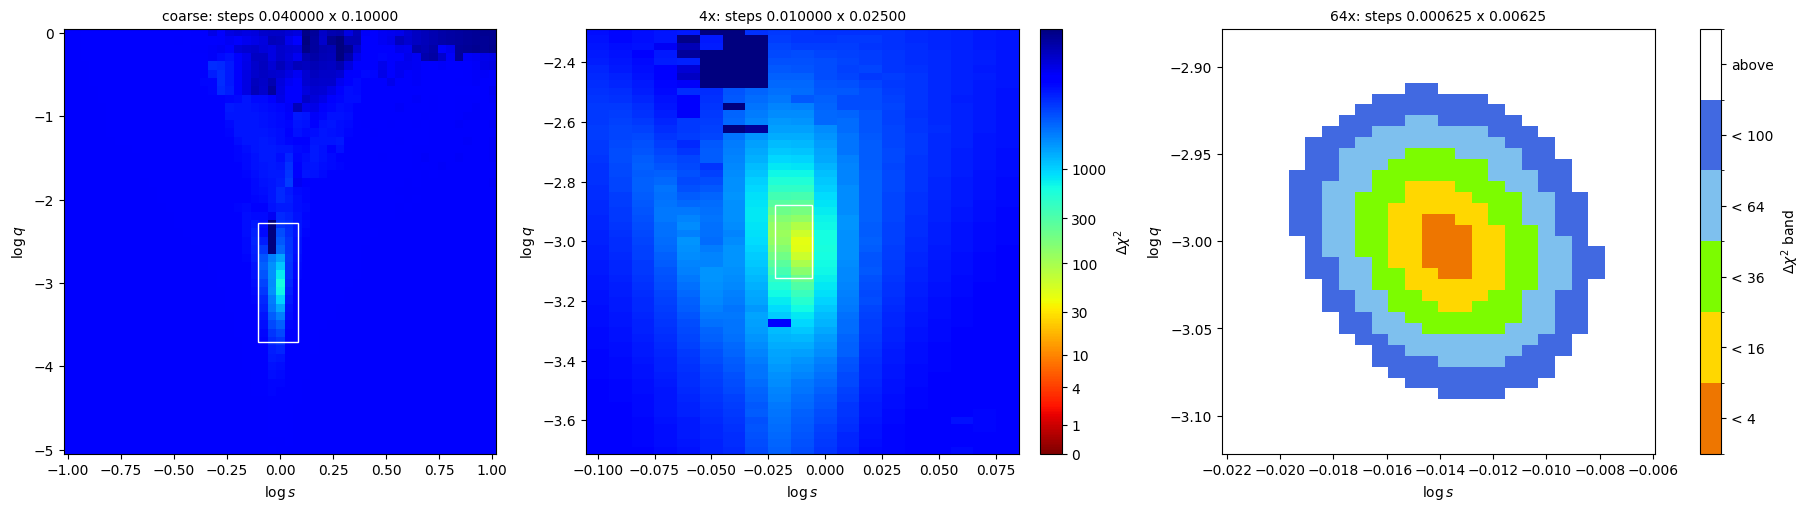

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
figures.plot_map(map1, ax=axs[0], vmax=30000, chi2_ref=ref, colorbar=False)
figures.plot_map(map4, ax=axs[1], vmax=30000, chi2_ref=ref)
figures.plot_map(map64, bands=(4, 16, 36, 64, 100), ax=axs[2], chi2_ref=ref)
for ax, (_, m) in zip(axs[:2], MAPS[1:]):
    hs, hq = (m["logs"][1] - m["logs"][0]) / 2, (m["logq"][1] - m["logq"][0]) / 2
    ax.add_patch(plt.Rectangle((m["logs"][0] - hs, m["logq"][0] - hq), m["logs"][-1] - m["logs"][0] + 2 * hs,
                               m["logq"][-1] - m["logq"][0] + 2 * hq, fill=False, ec="w", lw=1))
for ax, (name, m) in zip(axs, MAPS):
    ax.set_title(f"{name}: steps {m['logs'][1] - m['logs'][0]:.6f} x {m['logq'][1] - m['logq'][0]:.5f}", fontsize=10)

The coarse map shows a V again, with its tip at log *s* ≈ 0, log *q* ≈ −3. But this time the tip is a single valley,
and a very sharp one: the best coarse point is about 600 above the minimum, and the best 4× point still 46. Only the
64× box (steps 0.000625 × 0.00625) resolves it, as a single, nearly round minimum. Δχ² < 4 spans about 0.0015 dex
in log *s* and 0.02 dex in log *q*; Δχ² < 100 spans about ±0.006 in log *s* and ±0.08 in log *q*. Nothing else on the
map comes within 1000.

Why so sharp? The anomaly is shaped by the source passing within a few source radii of the cusps of a resonant
caustic, whose size and shape change quickly with *s* and *q* near the Einstein ring. A shift of 0.002 dex in *s*
already moves the cusps by a noticeable fraction of the source radius.

## 5. The best fit

In [9]:
best_file = "data/rmdc1576_best.json"
if RECOMPUTE or not os.path.exists(best_file):
    log("polishing the best fit")
    i, j = np.unravel_index(np.nanargmin(map64["chi2"]), map64["chi2"].shape)
    x = map64["pars"][i, j]
    starts = [np.array([x[0], x[1], x[2], map64["logs"][i], map64["logq"][j], x[3], x[4]]), best_first]
    c_b, p_b = min((lenscape.fit_full(data, p, be) for p in starts), key=lambda r: r[0])
    c_s, p_s = lenscape.fit_full(season, p_b, be, rounds=2, maxfev=4000)
    json.dump(dict(p_binned=list(p_b), p_season=list(p_s)), open(best_file, "w"), indent=1)
best = np.array(json.load(open(best_file))["p_season"])
print(f"t0 = {best[0]:.4f}, u0 = {best[1]:.5f}, tE = {best[2]:.3f} d, s = {10 ** best[3]:.5f}, q = {10 ** best[4]:.4e}, "
      f"alpha = {best[5]:.4f}, rho = {10 ** best[6]:.3e}")
r = model.residuals(be, best, season)
for k, n in enumerate(season.names):
    print(f"  {n}: chi2 / N = {np.sum(r[season.idx == k] ** 2):.1f} / {np.sum(season.idx == k)}")
fs, fb = model.fluxes(model.magnification(be, best, season), season)
for k, n in enumerate(season.names):
    print(f"  {n}: source flux {fs[k]:8.4f} uJy, blend {fb[k]:8.4f} uJy")

t0 = 1646.2038, u0 = 0.10387, tE = 7.161 d, s = 0.96878, q = 9.9264e-04, alpha = 5.5964, rho = 4.277e-03
  F087: chi2 / N = 242.2 / 240
  F146: chi2 / N = 7685.3 / 7673
  F213: chi2 / N = 251.4 / 239
  F087: source flux  -0.0051 uJy, blend   0.0216 uJy
  F146: source flux   1.4656 uJy, blend   3.3341 uJy
  F213: source flux  22.2167 uJy, blend  84.4003 uJy


| parameter | value |
|---|---|
| *t*₀ (BJD′) | 1646.204 |
| *u*₀ | 0.1039 |
| *t*ₑ | 7.16 d |
| *s* | 0.9688 |
| *q* | 9.93 × 10⁻⁴ |
| α | 5.596 rad |
| ρ | 4.28 × 10⁻³ |

χ²/N is 1.00 in each filter. In F087 the source flux is consistent with zero, as expected behind 12 mag of
extinction.

## 6. The light curve

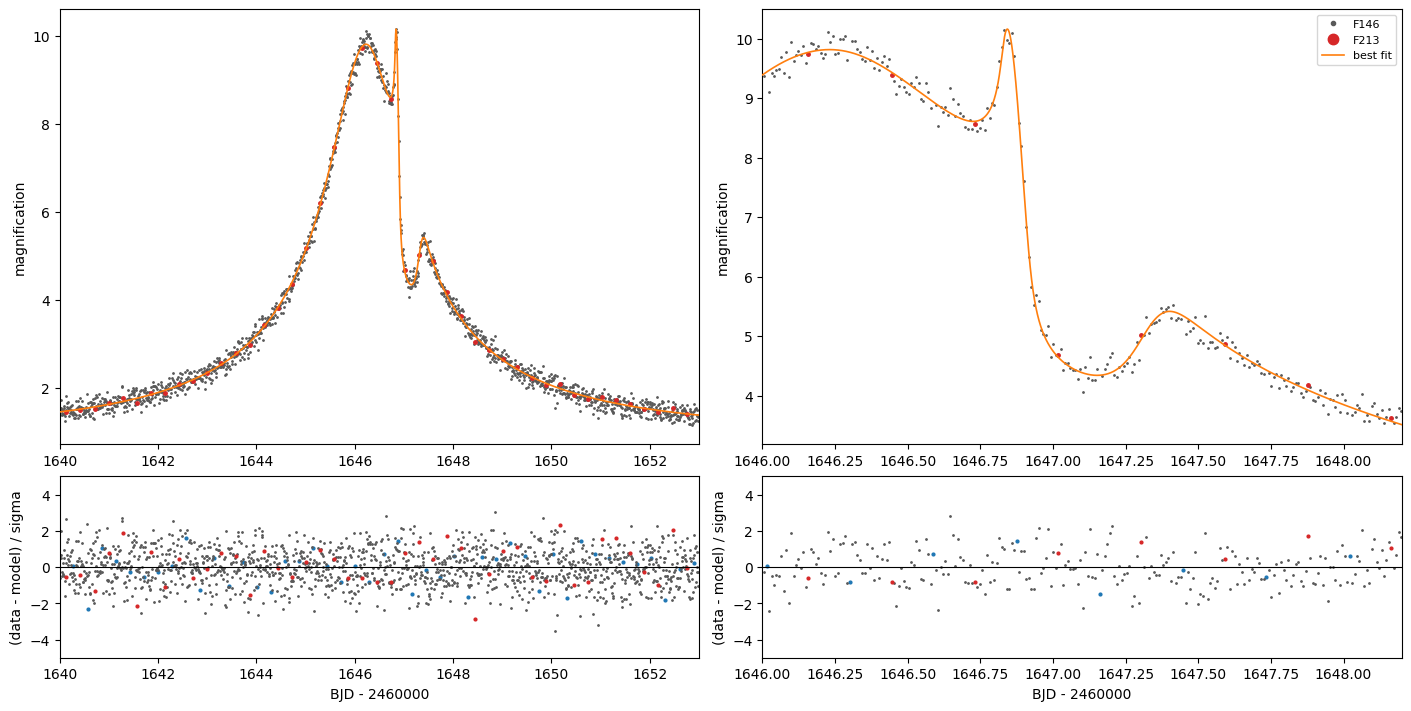

In [10]:
def plot_lc(p, d=season, window=(1640, 1653), zoom=(1646.0, 1648.2)):
    # F146 and F213 as magnifications implied by each point; model; residuals
    fs, fb = model.fluxes(model.magnification(be, p, d), d)
    fig = plt.figure(figsize=(14, 7), constrained_layout=True)
    gs = fig.add_gridspec(2, 2, height_ratios=[2.4, 1])
    for col, (a, b) in enumerate((window, zoom)):
        ax, axr = fig.add_subplot(gs[0, col]), fig.add_subplot(gs[1, col])
        res = model.residuals(be, p, d)
        for k, (n, c) in enumerate(zip(d.names, ["C0", "0.35", "C3"])):
            m = (d.idx == k) & (d.t > a) & (d.t < b)
            if n != "F087":
                ax.plot(d.t[m], (d.f[m] - fb[k]) / fs[k], ".", ms=2 if n == "F146" else 5, color=c, label=n, zorder=2)
            axr.plot(d.t[m], res[m], ".", ms=2 if n == "F146" else 4, color=c)
        tt = np.linspace(a, b, 4000)
        ax.plot(tt, be.lc(model.clamp(p)[0], tt), color="C1", lw=1.2, label="best fit", zorder=3)
        ax.set_xlim(a, b); ax.set_ylabel("magnification")
        axr.axhline(0, color="k", lw=0.8); axr.set_xlim(a, b); axr.set_ylim(-5, 5)
        axr.set_ylabel("(data - model) / sigma"); axr.set_xlabel("BJD - 2460000")
    ax.legend(fontsize=8, markerscale=3)
    return fig

plot_lc(best);

The light curve is drawn as magnification (the flux of each point with the fitted blend removed and divided by
the source flux), so that F146 and F213 fall on one curve. The model follows the whole anomaly: the peak at
magnification 9.8 (BJD′ 1646.2), a shallow dip, the spike to 10.2 at BJD′ 1646.84, the fall to 4.4 within about
five hours, the trough, and the second bump to 5.4 around BJD′ 1647.4. The residuals are flat in both filters (F087, all noise, is shown only in the residuals).

## 7. The caustic and the source trajectory

1 caustic curve(s)


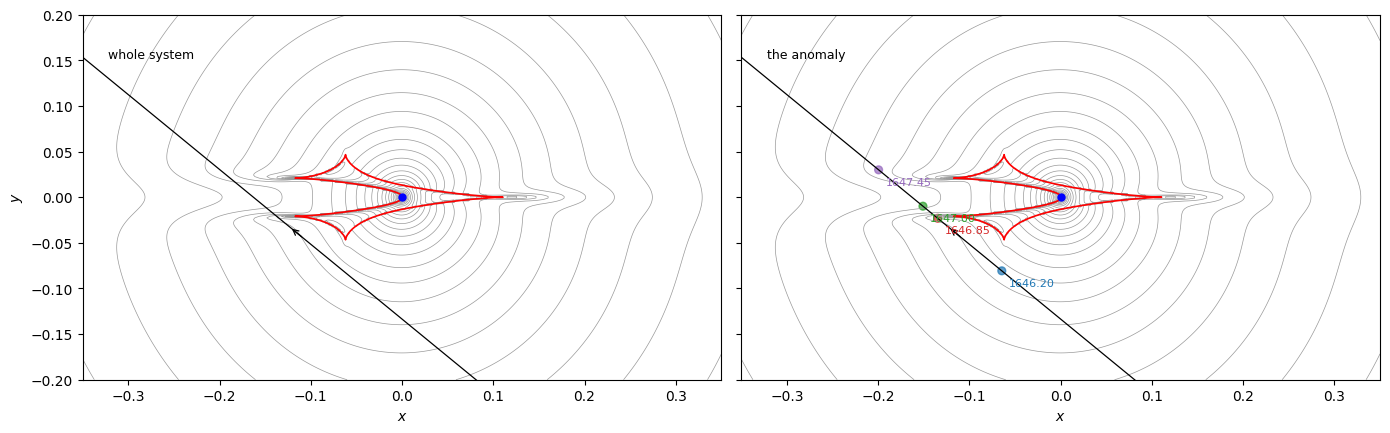

In [11]:
fig = figures.plot_geometry([best, best], labels=["whole system", "the anomaly"], ncols=2, figsize=(14, 5.5),
                            extent=(-0.35, 0.35, -0.2, 0.2), t_arrow=1646.6)
x0 = caustics.lens_positions(10 ** best[3], 10 ** best[4])[0]
rho = 10 ** best[6]
for ax in fig.axes[1:2]:
    for t, c in ((1646.2, "C0"), (1646.85, "C3"), (1647.0, "C2"), (1647.45, "C4")):
        z = caustics.trajectory(best, [t])[0]
        ax.add_patch(plt.Circle((z.real - x0, z.imag), rho, color=c, alpha=0.7))
        ax.annotate(f"{t:.2f}", (z.real - x0, z.imag), xytext=(5, -11), textcoords="offset points", fontsize=8, color=c)
print(f"{len(caustics.caustics(10 ** best[3], 10 ** best[4], 500))} caustic curve(s)")

With *s* = 0.969, just inside the Einstein ring, central and planetary caustics have merged into one resonant caustic
(red), 0.23 Einstein radii long and 0.09 wide, with the host near its middle. The source passes it on the side away
from the planet (the planet is at *x* = *s*, outside the panels), moving up and to the left. At BJD′ 1646.84 it
passes three source radii from the lower of the two back cusps (at *x* ≈ −0.12), which makes the spike; it then
leaves the caustic behind and crosses the demagnified region between the two back cusps, which makes the sudden
fall and the trough; the second bump around BJD′ 1647.4 comes from the ridge that runs out of the upper back cusp. The source never crosses the
caustic, but it comes close enough for its size to matter, so ρ is measured.

## 8. What kind of system is this?

**Measured.** A companion with *q* = 9.9 × 10⁻⁴ of its host's mass, almost exactly the Jupiter–Sun ratio
(9.5 × 10⁻⁴), at *s* = 0.969 Einstein radii, inside the resonant range. *t*ₑ = 7.2 d, and the source takes
ρ *t*ₑ = 44 minutes to cross its radius.

**Physical scale (rough).** The fit gives the source F146 = 23.48 and F213 = 20.53 (AB). With the challenge's
extinction (*A* = 4.93 and 1.66 mag) the source is F146₀ = 18.55 and (F146 − F213)₀ = −0.32, a source that would be
bright and blue for the bulge: at 8 kpc its absolute F146 magnitude is 4.0, 0.7 mag brighter than the Sun in the
near infrared (*H*_AB ≈ 4.7), so about 1.4 solar radii (a subgiant or turnoff star), θ⋆ ≈ 0.8 µas. With ρ that
gives θₑ ≈ 0.19 mas and μ ≈ 10 mas/yr.

In [12]:
theta_E = 0.80e-3 / 10 ** best[6]          # mas, from theta_* ~ 0.8 micro-arcsec (rough, see text)
DS = 8.0
print(f"theta_E = {theta_E:.3f} mas, mu_rel = {theta_E / best[2] * 365.25:.1f} mas/yr")
print(f"{'D_L (kpc)':>9s} {'M_host (Msun)':>13s} {'M_planet (MJup)':>15s} {'a_perp (AU)':>11s}")
for DL in (3.0, 5.0, 6.0, 7.0):
    M = theta_E ** 2 / (8.144 * (1 / DL - 1 / DS))
    print(f"{DL:9.1f} {M:13.3f} {10 ** best[4] * M * 1047.6:15.3f} {10 ** best[3] * theta_E * DL:11.2f}")

theta_E = 0.187 mas, mu_rel = 9.5 mas/yr
D_L (kpc) M_host (Msun) M_planet (MJup) a_perp (AU)
      3.0         0.021           0.021        0.54
      5.0         0.057           0.060        0.91
      6.0         0.103           0.107        1.09
      7.0         0.241           0.250        1.27


For lens distances of 3–7 kpc the host has 0.02–0.24 M_⊙, a brown dwarf or an M dwarf, and the companion
0.02–0.25 Jupiter masses (about 7–80 Earth masses, up to the mass of Saturn), at a projected 0.5–1.3 AU. A host in the bulge
(*D*_L ≈ 6–7 kpc) is the most likely; then this is a **Saturn-mass planet orbiting an M dwarf at about 1 AU**. The
same caveats as before apply: θ⋆ is rough (one colour, the Sun's surface brightness, the source distance), and
parallax is not fitted.

## 9. Summary

* The blind map of this resonant-caustic event has a single solution: a planet with *q* = 9.9 × 10⁻⁴ at *s* = 0.969,
  χ²/N = 1.00 on all 49 488 points. Nothing else is within 1000.
* The minimum is very sharp, because the source passes within a few source radii of the cusps of a resonant
  caustic. The coarse map misses it by about 600 and a 4× zoom by 46; only a 64× zoom resolves it. All maps
  together took 33 minutes.
* Not done: parallax, MCMC uncertainties, limb darkening, a proper physical analysis.

**References.** Penny, M. T., et al. 2019, ApJS, 241, 3. Roman Microlensing Data Challenge 2026, RGES-PIT,
[rges-pit.org/data-challenge](https://rges-pit.org/data-challenge/).